# Benchmark - Simulated Nanopore Read-Level Evaluation & Null Model

- **Part A (Run Badread Simulation, Read Scoring & Variable threshold impact):**
  1. **Badread Nanopore simulation (Section 10):** Generates synthetic amplicon constructs (`EQA_2026_05` template + primers) alongside `junk` and `random` negative controls across 3 noise profiles (`eqa_fit` trained on ECDC ESIB EQA 2026 reads, `hunt` Q20 model, and `r9_like` older R9.4.1 model) $\times$ 3 random seeds (`1`, `2`, `3` — 123,277 total reads).
  2. **Read-level truth scoring (Section 11):** Base-level confusion metrics (`construct` vs `junk` vs `random`) and boundary-level accuracy at $\pm 0, 1, 2, 5\text{ nt}$ tolerances across `bitvector_longest`, `sassy`, `semiglobal`, and controls (`oracle`, `no_trim`, `fixed_crop`).
  3. **Parameter threshold sweep & null-model evaluation (Section 12):** Grid evaluation on a 5,000-read sample per profile across error rate and identity settings.
- **Part B (Results & Visualization):** Base-level confusion metrics stratified by read class (`construct` vs `junk` vs `random`), and ROC curves (`per_end_tpr` vs `negative_end_fpr`)

**Caching:** same as the other notebooks

## Part A, Run Badread Simulation, Read Scoring & Parameter impact

In [2]:
from collections import Counter
from dataclasses import dataclass, replace
import hashlib
import json
import os
from pathlib import Path
import re
import shlex
import shutil
import subprocess
import sys
from typing import NamedTuple

import edlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import primer_matchers

MANUAL_DIR = ROOT / "manual_test"
DATASET_DIR = MANUAL_DIR / "datasets"
PROCESSED_DIR = MANUAL_DIR / "processed"
RESULTS_DIR = PROCESSED_DIR / "benchmark2"
SIM_DIR = RESULTS_DIR / "simulation"
SCORING_DIR = SIM_DIR / "scoring"
SWEEP_CACHE_DIR = SIM_DIR / "threshold_sweep" / "cache"

SIM_DIR.mkdir(parents=True, exist_ok=True)
SCORING_DIR.mkdir(parents=True, exist_ok=True)
SWEEP_CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Environment configuration: ensure tools from conda environment ampligone_thesis are used
ENV_PREFIX = Path(sys.prefix)
ENV_BIN = ENV_PREFIX / "bin"
BADREAD_BIN = ENV_BIN / "badread"
if not BADREAD_BIN.is_file():
    user_badread = Path.home() / "UserBinaries/envs/ampligone_thesis/bin/badread"
    if user_badread.is_file():
        BADREAD_BIN = user_badread

def run_cmd(command: str, cwd: Path | None = None) -> subprocess.CompletedProcess:
    env = dict(os.environ)
    env["PATH"] = f"{BADREAD_BIN.parent}{os.pathsep}{env.get('PATH', '')}"
    env["CONDA_PREFIX"] = str(BADREAD_BIN.parent.parent)
    return subprocess.run(
        ["bash", "-c", f"set -o pipefail; {command}"],
        cwd=cwd, env=env, capture_output=True, text=True, check=True
    )

def join_command(*parts) -> str:
    return " ".join(str(part) for part in parts if str(part))

def quote(path) -> str:
    return shlex.quote(str(path))

REFERENCE_ID = "MN908947.3"
REFERENCE_FASTA = MANUAL_DIR / "MN908947.fasta"
SIM_YEAR = "2026"
PRIMER_FASTA = DATASET_DIR / f"ESIB_EQA_{SIM_YEAR}.SARS1.primers.fasta"
PRIMER_BED = DATASET_DIR / f"ESIB_EQA_{SIM_YEAR}.SARS1.primers.bed"
ALIGN_FASTA = DATASET_DIR / f"ESIB_EQA_{SIM_YEAR}.SARS1.gold_standard.high_cov.alignment.fasta"

IDENTITY_PROFILES = {
    "eqa_fit": "98.81,99.90,2.07",
    "hunt": "94,98.5,3",
    "r9_like": "90,95,4",
}
SCORING_PROFILES = tuple(IDENTITY_PROFILES)
SIM_SEEDS = (1, 2, 3)
RANDOM_SEED = 42
SCORING_WORKERS = 8
TRIM_METHODS = ("bitvector_longest", "sassy", "semiglobal")
CONTROL_METHODS = ("oracle", "no_trim", "fixed_crop")
BOUNDARY_TOLERANCES = (0, 1, 2, 5)
PRIMER_MAX_LENGTH = max(len(primer.sequence) for primer in primer_matchers.read_primers(PRIMER_FASTA))

SOURCE_SAMPLE = "EQA_2026_05"
DEPTH_MEAN, DEPTH_SD = 500, 20
DROPOUT_RATE = 0.001
FRAGMENT_LENGTH = "50000,1000"
ARTEFACTS = ["--junk_reads", "1", "--random_reads", "1", "--chimeras", "1", "--glitches", "10000,25,25"]

print(f"Simulation directory: {SIM_DIR}")
print(f"Badread binary:       {BADREAD_BIN}")
print(f"Primer FASTA:         {PRIMER_FASTA} (max primer len={PRIMER_MAX_LENGTH} nt)")
print(f"Seeds:                {SIM_SEEDS} across profiles {SCORING_PROFILES}")

Simulation directory: /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2/simulation
Badread binary:       /home/zwagemaf/UserBinaries/envs/ampligone_thesis/bin/badread
Primer FASTA:         /home/zwagemaf/projects/AmpliGone_thesis/manual_test/datasets/ESIB_EQA_2026.SARS1.primers.fasta (max primer len=33 nt)
Seeds:                (1, 2, 3) across profiles ('eqa_fit', 'hunt', 'r9_like')


In [3]:
# 1. Badread Simulation (Section 10)

# Models resolution: check SIM_DIR/training; if missing, import from simulation2/training if available
TRAIN_DIR = SIM_DIR / "training"
TRAIN_DIR.mkdir(parents=True, exist_ok=True)
ERROR_MODEL = TRAIN_DIR / "eqa.error_model"
QSCORE_MODEL = TRAIN_DIR / "eqa.qscore_model"
IDENTITY_FILE = TRAIN_DIR / "identity_profiles.json"

SOURCE_TRAIN_DIR = PROCESSED_DIR / "benchmark2" / "simulation2" / "training"
if not ERROR_MODEL.is_file() and (SOURCE_TRAIN_DIR / "eqa.error_model").is_file():
    shutil.copy2(SOURCE_TRAIN_DIR / "eqa.error_model", ERROR_MODEL)
if not QSCORE_MODEL.is_file() and (SOURCE_TRAIN_DIR / "eqa.qscore_model").is_file():
    shutil.copy2(SOURCE_TRAIN_DIR / "eqa.qscore_model", QSCORE_MODEL)
if not IDENTITY_FILE.is_file() and (SOURCE_TRAIN_DIR / "identity_profiles.json").is_file():
    shutil.copy2(SOURCE_TRAIN_DIR / "identity_profiles.json", IDENTITY_FILE)

if IDENTITY_FILE.is_file():
    IDENTITY_PROFILES = json.loads(IDENTITY_FILE.read_text())

# Scheme & primer parsing
PRIMER_NAME = re.compile(r"^(?:ncov-2019|sars-cov-2)_(\d+)_(?:(alt\d*)_)?(LEFT|RIGHT)(?:_(alt\d*|\d+))?$", re.IGNORECASE)

class PrimerName(NamedTuple):
    amplicon: int
    side: str
    is_alt: bool

def parse_primer_name(name: str) -> PrimerName | None:
    match = PRIMER_NAME.fullmatch(name)
    if match is None:
        return None
    tag = match.group(2) or match.group(4)
    return PrimerName(int(match.group(1)), match.group(3).upper(), tag not in (None, "1"))

def read_fasta_records(path: Path) -> dict[str, str]:
    records = {}
    name = None
    for line in path.read_text().splitlines():
        if line.startswith(">"):
            name = line[1:].split()[0]
            records[name] = []
        elif name:
            records[name].append(line.strip().upper())
    return {k: "".join(v) for k, v in records.items()}

bed = pd.read_csv(PRIMER_BED, sep="\t", header=None, usecols=range(6),
                  names=["contig", "start", "end", "name", "score", "strand"])
parsed = [parse_primer_name(name) for name in bed["name"]]
bed = bed.assign(amplicon=[p.amplicon for p in parsed], side=[p.side for p in parsed],
                 is_alt=[p.is_alt for p in parsed])
fasta_records = read_fasta_records(PRIMER_FASTA)
by_key = {}
for name, sequence in fasta_records.items():
    p = parse_primer_name(name)
    if p:
        by_key.setdefault((p.amplicon, p.side, p.is_alt), sequence)
bed["sequence"] = [by_key.get((a, s, t)) for a, s, t in zip(bed["amplicon"], bed["side"], bed["is_alt"])]
primary_bed = bed[~bed["is_alt"]]
PRIMER_SEQUENCES = dict(zip(primary_bed["name"], primary_bed["sequence"]))

amplicon_ends = {}
for amplicon, group in primary_bed.groupby("amplicon"): 
    left = group[group["side"] == "LEFT"]
    right = group[group["side"] == "RIGHT"]
    if len(left) and len(right):
        amplicon_ends[int(amplicon)] = (left.sort_values("start").iloc[0], right.sort_values("end").iloc[-1])

# Curated reference & template for held-out sample EQA_2026_05
aln_records = read_fasta_records(ALIGN_FASTA)
ref_row = aln_records[REFERENCE_ID]
sample_row = aln_records["ESIB_EQA_2026_SARS1_05"]

ref_indices = []
cur_ref = 0
for r in ref_row:
    if r != "-":
        ref_indices.append(cur_ref)
        cur_ref += 1
    else:
        ref_indices.append(cur_ref)

chars, ref_pos = [], []
for r, s, pos in zip(ref_row, sample_row, ref_indices):
    if s == "-":
        continue
    elif s in "ACGT":
        chars.append(s)
        ref_pos.append(pos)
    else:
        chars.append(r)
        ref_pos.append(pos)

curated_sequence = np.array(chars)
curated_ref_pos = np.array(ref_pos)

COMPLEMENT = str.maketrans("ACGTN", "TGCAN")
def revcomp(seq: str) -> str:
    return seq.translate(COMPLEMENT)[::-1]

def site_sequence(seq: np.ndarray, pos: np.ndarray, start: int, end: int) -> str:
    return "".join(seq[(pos >= start) & (pos < end)])

def mismatch_count(site: str, oligo: str) -> int:
    if len(site) != len(oligo):
        return max(len(site), len(oligo))
    return sum(a != b for a, b in zip(site, oligo))

def build_constructs(sample: str, rng: np.random.Generator) -> tuple[dict[int, str], pd.DataFrame]:
    constructs, rows = {}, []
    for amplicon, (left, right) in amplicon_ends.items():
        left_oligo = PRIMER_SEQUENCES[left["name"]]
        right_oligo = revcomp(PRIMER_SEQUENCES[right["name"]])
        template = site_sequence(curated_sequence, curated_ref_pos, left["end"], right["start"])
        mismatches = (
            mismatch_count(site_sequence(curated_sequence, curated_ref_pos, left["start"], left["end"]), left_oligo)
            + mismatch_count(site_sequence(curated_sequence, curated_ref_pos, right["start"], right["end"]), right_oligo)
        )
        dropped = mismatches > 0 and rng.random() < 0.5
        if not dropped:
            constructs[amplicon] = left_oligo + template + right_oligo
        rows.append({
            "sample": sample,
            "amplicon": amplicon,
            "left": left["name"],
            "right": right["name"],
            "left_len": len(left_oligo),
            "right_len": len(right_oligo),
            "construct_len": len(left_oligo) + len(template) + len(right_oligo),
            "mismatches": mismatches,
            "kept": not dropped,
        })
    return constructs, pd.DataFrame(rows)

rng = np.random.default_rng(RANDOM_SEED)
CONSTRUCTS_05, construct_table_05 = build_constructs(SOURCE_SAMPLE, rng)
CONSTRUCT_CSV = SIM_DIR / "constructs.csv"
if not CONSTRUCT_CSV.is_file():
    construct_table_05.to_csv(CONSTRUCT_CSV, index=False)
source_meta = construct_table_05[construct_table_05["kept"]].set_index("amplicon")

# Base-by-base truth labeling using edlib alignment against the source construct
ORIGIN = re.compile(r"(?P<contig>[^,\s]+),(?P<strand>[+-])strand,(?P<start>\d+)-(?P<end>\d+)")
IDENTITY = re.compile(r"read_identity=([\d.]+)%")
CIGAR_OP = re.compile(r"(\d+)([=XIDM])")
READ_ONLY_OP, CONSTRUCT_ONLY_OP = "D", "I"

def label_read(sequence: str, strand: str, construct: str, left_len: int, right_len: int) -> dict:
    oriented = sequence if strand == "+" else revcomp(sequence)
    alignment = edlib.align(construct, oriented, mode="HW", task="path")
    read_start, _ = alignment["locations"][0]
    construct_len = len(construct)

    def segment(position: int) -> str:
        if position < left_len:
            return "L"
        if position >= construct_len - right_len:
            return "R"
        return "I"

    codes = ["o"] * len(oriented)
    q, t = read_start, 0
    construct_start = construct_end = None
    for count, op in CIGAR_OP.findall(alignment["cigar"]):
        for _ in range(int(count)):
            if op == READ_ONLY_OP:
                neighbours = {segment(p) for p in (t - 1, t) if 0 <= p < construct_len}
                codes[q] = neighbours.pop() if len(neighbours) == 1 else "x"
                q += 1
            elif op == CONSTRUCT_ONLY_OP:
                t += 1
            else:
                if construct_start is None:
                    construct_start = t
                codes[q] = segment(t)
                q += 1
                t += 1
                construct_end = t
    labels = "".join(codes)
    if strand == "-":
        labels = labels[::-1]
    return {
        "labels": labels,
        "construct_start": construct_start,
        "construct_end": construct_end,
        "edit_distance": alignment["editDistance"],
    }

def simulate_amplicon(amplicon: int, construct: str, meta: pd.Series, depth: int, profile: str,
                      seed: int, run_dir: Path, reads_out) -> list[dict]:
    fasta = run_dir / f"amp{amplicon:03d}.fasta"
    fasta.write_text(f">amp{amplicon:03d}\n{construct}\n")
    fastq = run_dir / f"amp{amplicon:03d}.fastq"
    cmd = join_command(
        quote(BADREAD_BIN), "simulate --reference", quote(fasta), "--quantity", f"{depth}x",
        "--length", FRAGMENT_LENGTH, "--identity", IDENTITY_PROFILES[profile],
        "--error_model", quote(ERROR_MODEL), "--qscore_model", quote(QSCORE_MODEL),
        "--seed", RANDOM_SEED + 1000 * seed + amplicon, *ARTEFACTS, "> ", quote(fastq),
    )
    run_cmd(cmd)
    lines = fastq.read_text().splitlines()
    fastq.unlink()
    fasta.unlink()
    rows = []
    for header, sequence, plus, quality in zip(lines[0::4], lines[1::4], lines[2::4], lines[3::4]):
        name, origin = header[1:].split(" ")[:2]
        reads_out.write(f"{header}\n{sequence}\n{plus}\n{quality}\n")
        row = {
            "read": name,
            "amplicon": None,
            "read_length": len(sequence),
            "identity": float(IDENTITY.search(header).group(1)),
            "construct_len": len(construct),
        }
        if origin in ("junk_seq", "random_seq"): 
            row.update(**{"class": origin.replace("_seq", ""), "labels": "n" * len(sequence)})
        else:
            match = ORIGIN.fullmatch(origin)
            if match is None or match["contig"] != f"amp{amplicon:03d}":
                row.update(**{"class": "unparsed", "labels": "u" * len(sequence)})
            else:
                aligned = label_read(sequence, match["strand"], construct,
                                     int(meta["left_len"]), int(meta["right_len"]))
                row.update(**{
                    "class": "construct",
                    "amplicon": amplicon,
                    "strand": match["strand"],
                    "header_start": int(match["start"]),
                    "header_end": int(match["end"]),
                    **aligned,
                })
        rows.append(row)
    return rows

def simulate_set(profile: str, seed: int, constructs: dict[int, str], meta: pd.DataFrame) -> pd.DataFrame:
    out_dir = SIM_DIR / profile / f"seed{seed}"
    run_dir = out_dir / "runs"
    run_dir.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(RANDOM_SEED + seed)
    rows = []
    with (out_dir / "reads.fastq").open("w") as reads_out:
        for amplicon, construct in constructs.items():
            if rng.random() < DROPOUT_RATE:
                continue
            depth = int(round(rng.normal(DEPTH_MEAN, DEPTH_SD)))
            rows += simulate_amplicon(amplicon, construct, meta.loc[amplicon], depth, profile, seed, run_dir, reads_out)
    shutil.rmtree(run_dir, ignore_errors=True)
    labels = pd.DataFrame(rows)
    labels.to_csv(out_dir / "labels.tsv.gz", sep="\t", index=False)
    return labels

def simulation_checks(labels: pd.DataFrame) -> dict:
    built = labels[labels["class"] == "construct"]
    full_length = (built["header_start"] == 0) & (built["header_end"] == built["construct_len"])
    coords_agree = (built["construct_start"] == built["header_start"]) & (built["construct_end"] == built["header_end"])
    counts = labels["class"].value_counts()
    return {
        "reads": len(labels),
        "construct": int(counts.get("construct", 0)),
        "junk": int(counts.get("junk", 0)),
        "random": int(counts.get("random", 0)),
        "unparsed": int(counts.get("unparsed", 0)),
        "full_length": round(float(full_length.mean()), 4) if len(built) else 0.0,
        "coords_agree": round(float(coords_agree.mean()), 4) if len(built) else 0.0,
    }

# Execute or verify simulation sets
checks = []
for seed in SIM_SEEDS:
    for profile in SCORING_PROFILES:
        out_dir = SIM_DIR / profile / f"seed{seed}"
        labels_path = out_dir / "labels.tsv.gz"
        reads_path = out_dir / "reads.fastq"
        if labels_path.is_file() and reads_path.is_file():
            labels = pd.read_csv(labels_path, sep="\t")
            print(f"Verified simulated set {profile} seed {seed} ({len(labels)} reads)")
        else:
            print(f"Simulating {profile} seed {seed} with Badread...")
            out_dir.mkdir(parents=True, exist_ok=True)
            labels = simulate_set(profile, seed, CONSTRUCTS_05, source_meta)
        checks.append({"profile": profile, "seed": seed, **simulation_checks(labels)})

SIM_CHECKS = pd.DataFrame(checks)
SIM_CHECKS.to_csv(SIM_DIR / "simulation_checks.csv", index=False)
display(SIM_CHECKS)

Verified simulated set eqa_fit seed 1 (13183 reads)
Verified simulated set hunt seed 1 (14692 reads)
Verified simulated set r9_like seed 1 (14742 reads)
Verified simulated set eqa_fit seed 2 (13855 reads)
Verified simulated set hunt seed 2 (14273 reads)
Verified simulated set r9_like seed 2 (14619 reads)
Verified simulated set eqa_fit seed 3 (14361 reads)
Verified simulated set hunt seed 3 (13092 reads)
Verified simulated set r9_like seed 3 (14965 reads)


,profile,seed,reads,construct,junk,random,unparsed,full_length,coords_agree
0,eqa_fit,1,13183,12900,149,134,0,1.0,0.9609
1,hunt,1,14692,14411,136,145,0,1.0,0.8485
2,r9_like,1,14742,14470,147,125,0,1.0,0.7957
3,eqa_fit,2,13855,13569,140,146,0,1.0,0.9662
4,hunt,2,14273,13989,131,153,0,1.0,0.8595
5,r9_like,2,14619,14332,156,131,0,1.0,0.7928
6,eqa_fit,3,14361,14088,134,139,0,1.0,0.9671
7,hunt,3,13092,12811,144,137,0,1.0,0.8502
8,r9_like,3,14965,14702,127,136,0,1.0,0.7905


In [4]:
# 2. Score Simulated Reads (Section 11)

def control_cuts(labels: pd.DataFrame, method: str) -> pd.DataFrame:
    length = labels["read_length"].to_numpy()
    if method == "no_trim":
        start, end = np.zeros(len(labels), dtype=int), length
    elif method == "fixed_crop":
        start = np.minimum(PRIMER_MAX_LENGTH, length)
        end = np.maximum(length - PRIMER_MAX_LENGTH, start)
    elif method == "oracle":
        start, end = [], []
        for text in labels["labels"]:
            first, last = text.find("I"), text.rfind("I")
            start.append(first if first >= 0 else 0)
            end.append(last + 1 if last >= 0 else 0)
        start, end = np.array(start), np.array(end)
    else:
        raise ValueError(f"Unknown control {method!r}")
    return pd.DataFrame({"read": labels["read"], "retained_start": start, "retained_end": end})

def run_trim(source: Path, method: str, output: Path, calls: Path) -> pd.DataFrame:
    trimmer = primer_matchers.create_trimmer(method, None if method == "adapters" else PRIMER_FASTA)
    primer_matchers.trim_fastq(trimmer, source, output, calls_path=calls, workers=SCORING_WORKERS)
    return pd.read_csv(calls, sep="\t", usecols=["read_id", "retained_start", "retained_end"])

def compose_cuts(first: pd.DataFrame, second: pd.DataFrame) -> pd.DataFrame:
    start = first["retained_start"] + second["retained_start"]
    end = first["retained_start"] + second["retained_end"]
    return pd.DataFrame({"read": first["read_id"], "retained_start": start, "retained_end": end})

def per_read_stats(labels: pd.DataFrame, cuts: pd.DataFrame) -> pd.DataFrame:
    table = labels[["read", "class", "labels"]].merge(cuts, on="read", how="left", validate="one_to_one")
    rows = []
    for read_class, text, start, end in table[["class", "labels", "retained_start", "retained_end"]].itertuples(index=False):
        truth = np.frombuffer(text.encode(), dtype=np.uint8)
        start, end = int(start), int(end)
        keep = np.zeros(len(truth), dtype=bool)
        keep[start:end] = True
        amplicon = truth == ord("I")
        removable = ~amplicon & (truth != ord("x"))
        row = {
            "class": read_class,
            "tp": int((~keep & removable).sum()),
            "fp": int((~keep & amplicon).sum()),
            "fn": int((keep & removable).sum()),
            "tn": int((keep & amplicon).sum()),
            "boundary": np.nan, "left_error": np.nan, "right_error": np.nan,
        }
        inside = np.flatnonzero(amplicon)
        if read_class == "construct" and len(inside):
            row.update(boundary=1.0, left_error=start - int(inside[0]), right_error=int(inside[-1]) + 1 - end)
        rows.append(row)
    stats = pd.DataFrame(rows)
    boundary = stats["boundary"].notna()
    for name, error in (("left", stats["left_error"]), ("right", stats["right_error"])):
        for tolerance in BOUNDARY_TOLERANCES:
            stats[f"{name}_within{tolerance}"] = (error.abs() <= tolerance).astype(float).where(boundary)
        stats[f"{name}_over"] = (error > 0).astype(float).where(boundary)
        stats[f"{name}_under"] = (error < 0).astype(float).where(boundary)
        stats[f"{name}_over_bases"] = error.clip(lower=0).where(boundary)
        stats[f"{name}_under_bases"] = (-error).clip(lower=0).where(boundary)
    stats["both_exact"] = stats["left_within0"] * stats["right_within0"]
    return stats.drop(columns=["left_error", "right_error"])

def score_set(profile: str, seed: int) -> pd.DataFrame:
    set_dir = SIM_DIR / profile / f"seed{seed}"
    scratch = SCORING_DIR / profile / f"seed{seed}"
    scratch.mkdir(parents=True, exist_ok=True)
    labels = pd.read_csv(set_dir / "labels.tsv.gz", sep="\t")
    cuts = {method: control_cuts(labels, method) for method in CONTROL_METHODS}
    adapter_fastq = scratch / "adapters.fastq"
    try:
        adapter_cuts = run_trim(set_dir / "reads.fastq", "adapters", adapter_fastq, scratch / "adapters.calls.tsv")
        for method in TRIM_METHODS:
            primer_fastq = scratch / f"{method}.fastq"
            primer_cuts = run_trim(adapter_fastq, method, primer_fastq, scratch / f"{method}.calls.tsv")
            primer_fastq.unlink(missing_ok=True)
            cuts[method] = compose_cuts(adapter_cuts, primer_cuts)
    finally:
        adapter_fastq.unlink(missing_ok=True)
    stats = [per_read_stats(labels, table).assign(profile=profile, method=method) for method, table in cuts.items()]
    return pd.concat(stats, ignore_index=True).assign(reads=1.0).groupby(["profile", "method", "class"], sort=False).sum(numeric_only=True).reset_index()

def confusion_metrics(counts: pd.DataFrame) -> pd.DataFrame:
    tp, fp, fn, tn = (counts[name].astype(float) for name in ("tp", "fp", "fn", "tn"))
    metrics = pd.DataFrame({
        "removal_sensitivity": tp / (tp + fn),
        "keep_specificity": tn / (tn + fp),
        "removal_precision": tp / (tp + fp),
        "npv": tn / (tn + fn),
        "fpr": fp / (fp + tn),
        "fnr": fn / (tp + fn),
        "fdr": fp / (tp + fp),
        "f1": 2 * tp / (2 * tp + fp + fn),
        "mcc": (tp * tn - fp * fn) / np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)),
        "balanced_accuracy": (tp / (tp + fn) + tn / (tn + fp)) / 2,
        "accuracy": (tp + tn) / (tp + fp + fn + tn),
    }, index=counts.index).replace([np.inf, -np.inf], np.nan)
    return pd.concat([counts, metrics], axis=1)

def boundary_metrics(counts: pd.DataFrame) -> pd.DataFrame:
    n = counts["boundary"]
    metrics = pd.DataFrame(index=counts.index)
    for name in ("left", "right"):
        for tolerance in BOUNDARY_TOLERANCES:
            metrics[f"{name}_exact_within{tolerance}"] = counts[f"{name}_within{tolerance}"] / n
        metrics[f"{name}_over_rate"] = counts[f"{name}_over"] / n
        metrics[f"{name}_under_rate"] = counts[f"{name}_under"] / n
        metrics[f"{name}_over_bases_mean"] = counts[f"{name}_over_bases"] / n
        metrics[f"{name}_under_bases_mean"] = counts[f"{name}_under_bases"] / n
    metrics["both_exact"] = counts["both_exact"] / n
    metrics["boundary_reads"] = n
    return metrics

set_tables = []
for profile in SCORING_PROFILES:
    for seed in SIM_SEEDS:
        cache = SCORING_DIR / profile / f"seed{seed}" / "set_counts.csv"
        if cache.is_file():
            table = pd.read_csv(cache)
        else:
            print(f"Scoring {profile} seed {seed}...")
            table = score_set(profile, seed).assign(seed=seed)
            cache.parent.mkdir(parents=True, exist_ok=True)
            table.to_csv(cache, index=False)
        set_tables.append(table)

SET_COUNTS = pd.concat(set_tables, ignore_index=True)
COUNTS = SET_COUNTS.drop(columns="seed").groupby(["profile", "method", "class"]).sum(numeric_only=True).reset_index()

CLASS_CONFUSION = confusion_metrics(COUNTS.drop(columns="profile").groupby(["method", "class"]).sum(numeric_only=True))
OVERALL_CONFUSION = confusion_metrics(COUNTS.drop(columns=["profile", "class"]).groupby("method").sum(numeric_only=True))
PROFILE_CONFUSION = confusion_metrics(COUNTS.set_index(["profile", "method", "class"]))

construct_counts = COUNTS[COUNTS["class"].eq("construct")]
BOUNDARY_POOLED = boundary_metrics(construct_counts.drop(columns=["profile", "class"]).groupby("method").sum(numeric_only=True))
BOUNDARY_BY_PROFILE = boundary_metrics(construct_counts.drop(columns="class").groupby(["profile", "method"]).sum(numeric_only=True))

for path, df in (
    (RESULTS_DIR / "scoring_confusion_by_class.csv", CLASS_CONFUSION),
    (RESULTS_DIR / "scoring_confusion_overall.csv", OVERALL_CONFUSION),
    (RESULTS_DIR / "scoring_confusion_by_profile.csv", PROFILE_CONFUSION),
    (RESULTS_DIR / "scoring_boundary_pooled.csv", BOUNDARY_POOLED),
    (RESULTS_DIR / "scoring_boundary_by_profile.csv", BOUNDARY_BY_PROFILE),
):
    if not path.is_file():
        df.to_csv(path)

print("Simulation read-level scoring tables verified on disk.")

Simulation read-level scoring tables verified on disk.


In [5]:
# 3. Parameter Threshold Sweep & Null-Model Evaluation (Section 12)

SWEEP_METHODS = ("bitvector_longest", "sassy", "semiglobal")
SWEEP_ERROR_RATES = tuple(sorted({round(float(v), 2) for v in np.arange(0.10, 0.401, 0.05)} | {0.22}))
SWEEP_IDENTITIES = (0.60, 0.65, 0.70, 0.75, 0.80)
SWEEP_SCORE_FRACTIONS = (0.50, 0.65, 0.80)
SWEEP_READS_PER_PROFILE = 5_000
SWEEP_NULL_BIN_WIDTH = 200
SWEEP_RESULT_PATH = SIM_DIR / "threshold_sweep.csv"
NULL_RESULT_PATH = SIM_DIR / "null_model.csv"

def threshold_configurations() -> list[tuple[str, dict[str, float]]]:
    configurations = []
    for method in ("bitvector_longest", "sassy"): 
        configurations.extend((method, {"max_error_rate": rate}) for rate in SWEEP_ERROR_RATES)
    configurations.extend(
        ("semiglobal", {"min_identity": identity, "min_score_fraction": score_fraction})
        for identity in SWEEP_IDENTITIES
        for score_fraction in SWEEP_SCORE_FRACTIONS
    )
    return configurations

def is_default_configuration(method: str, parameters: dict[str, float]) -> bool:
    defaults = {
        "bitvector_longest": {"max_error_rate": primer_matchers.BitvectorSettings().max_error_rate},
        "sassy": {"max_error_rate": primer_matchers.SassySettings().max_error_rate},
        "semiglobal": {
            "min_identity": primer_matchers.SemiglobalSettings().min_identity,
            "min_score_fraction": primer_matchers.SemiglobalSettings().min_score_fraction,
        },
    }[method]
    return all(np.isclose(parameters[name], value) for name, value in defaults.items())

def make_threshold_trimmer(method: str, parameters: dict[str, float]):
    if method == "bitvector_longest":
        settings = replace(primer_matchers.BitvectorSettings(), **parameters)
        trimmer = primer_matchers.BitvectorLongestRemover(PRIMER_FASTA, settings)
    elif method == "sassy":
        settings = replace(primer_matchers.SassySettings(), **parameters)
        trimmer = primer_matchers.SassyRemover(PRIMER_FASTA, settings)
    elif method == "semiglobal":
        settings = replace(primer_matchers.SemiglobalSettings(), **parameters)
        trimmer = primer_matchers.SemiglobalRemover(PRIMER_FASTA, settings)
    else:
        raise ValueError(f"Unknown sweep method {method!r}")
    if method in primer_matchers.TWO_PASS_METHODS:
        trimmer = primer_matchers.TwoPassTrimmer(trimmer)
    return trimmer

def load_threshold_sample(profile: str, sample_size: int = SWEEP_READS_PER_PROFILE):
    label_frames = []
    for seed in SIM_SEEDS:
        label_path = SIM_DIR / profile / f"seed{seed}" / "labels.tsv.gz"
        fastq_path = SIM_DIR / profile / f"seed{seed}" / "reads.fastq"
        if not label_path.is_file() or not fastq_path.is_file():
            raise FileNotFoundError(f"Missing simulated reads or labels for {profile} seed {seed}")
        frame = pd.read_csv(label_path, sep="\t", usecols=["read", "class", "labels", "read_length"])
        frame["seed"] = seed
        label_frames.append(frame)

    all_labels = pd.concat(label_frames, ignore_index=True)
    selected_frames = []
    base_target, remainder = divmod(sample_size, len(SIM_SEEDS))
    for seed_index, seed in enumerate(SIM_SEEDS):
        target = base_target + (seed_index < remainder)
        seed_labels = all_labels[all_labels["seed"] == seed]
        negatives = seed_labels[seed_labels["class"].isin(("junk", "random"))]
        constructs = seed_labels[seed_labels["class"] == "construct"]
        if len(negatives) > target:
            negatives = negatives.sample(n=target, random_state=RANDOM_SEED + seed)
        construct_count = target - len(negatives)
        if len(constructs) < construct_count:
            raise ValueError(f"Not enough construct reads for {profile} seed {seed}: {len(constructs)}")
        selected_constructs = constructs.sample(n=construct_count, random_state=RANDOM_SEED + seed)
        selected_frames.append(pd.concat([selected_constructs, negatives], ignore_index=True))

    selected = pd.concat(selected_frames, ignore_index=True)
    selected_ids = {seed: set(selected.loc[selected["seed"] == seed, "read"].astype(str)) for seed in SIM_SEEDS}
    records_by_id = {}
    for seed in SIM_SEEDS:
        if not selected_ids[seed]:
            continue
        fastq_path = SIM_DIR / profile / f"seed{seed}" / "reads.fastq"
        for record in primer_matchers.read_fastq(fastq_path):
            read_id = record.title.lstrip("@").split()[0]
            if read_id in selected_ids[seed]:
                records_by_id[read_id] = record
    records = [records_by_id[read_id] for read_id in selected["read"].astype(str)]
    return selected.reset_index(drop=True), records

def score_threshold_case(profile: str, method: str, parameters: dict[str, float],
                         labels: pd.DataFrame, adapter_results: list) -> tuple[dict, pd.DataFrame]:
    trimmer = make_threshold_trimmer(method, parameters)
    primer_results = trimmer.trim_records([result.record for result in adapter_results])
    totals = Counter()
    null_totals = Counter()
    null_by_length = Counter()

    for label_row, primer_result in zip(labels.rename(columns={"class": "class_"}).itertuples(index=False), primer_results):
        read_class = label_row.class_
        read_length = label_row.read_length
        if read_class == "construct":
            truth = np.frombuffer(label_row.labels.encode(), dtype=np.uint8)
            retained_start = primer_result.left_removed
            retained_end = read_length - primer_result.right_removed
            keep = np.zeros(len(truth), dtype=bool)
            keep[retained_start:retained_end] = True
            amplicon = truth == ord("I")
            removable = ~amplicon & (truth != ord("x"))
            totals["tp"] += int((~keep & removable).sum())
            totals["fp"] += int((~keep & amplicon).sum())
            totals["fn"] += int((keep & removable).sum())
            totals["tn"] += int((keep & amplicon).sum())
            left_primer = truth == ord("L")
            right_primer = truth == ord("R")
            if left_primer.any():
                totals["positive_ends"] += 1
                totals["called_ends"] += int(primer_result.left_removed > 0)
            if right_primer.any():
                totals["positive_ends"] += 1
                totals["called_ends"] += int(primer_result.right_removed > 0)
            inside = np.flatnonzero(amplicon)
            if len(inside):
                left_error = retained_start - int(inside[0])
                right_error = int(inside[-1]) + 1 - retained_end
                if left_primer.any():
                    totals["left_boundary_ends"] += 1
                    totals["left_exact"] += int(left_error == 0)
                    totals["left_within2"] += int(abs(left_error) <= 2)
                if right_primer.any():
                    totals["right_boundary_ends"] += 1
                    totals["right_exact"] += int(right_error == 0)
                    totals["right_within2"] += int(abs(right_error) <= 2)
                if left_primer.any() and right_primer.any():
                    totals["both_boundary_reads"] += 1
                    totals["both_exact"] += int(left_error == 0 and right_error == 0)
        elif read_class in ("junk", "random"): 
            length_lower = (read_length // SWEEP_NULL_BIN_WIDTH) * SWEEP_NULL_BIN_WIDTH
            called_ends = int(primer_result.left_removed > 0) + int(primer_result.right_removed > 0)
            null_totals[(read_class, "reads")] += 1
            null_totals[(read_class, "called_ends")] += called_ends
            null_by_length[(read_class, length_lower, "reads")] += 1
            null_by_length[(read_class, length_lower, "called_ends")] += called_ends

    configuration = {"profile": profile, "method": method, **parameters,
                     "is_default": is_default_configuration(method, parameters)}
    precision_denominator = totals["tp"] + totals["fp"]
    recall_denominator = totals["tp"] + totals["fn"]
    insert_denominator = totals["fp"] + totals["tn"]
    negative_ends = sum(null_totals[(rc, "reads")] * 2 for rc in ("junk", "random"))
    negative_calls = sum(null_totals[(rc, "called_ends")] for rc in ("junk", "random"))
    summary = {
        **configuration,
        "construct_reads": int(labels["class"].eq("construct").sum()),
        "base_tp": totals["tp"], "base_fp": totals["fp"], "base_fn": totals["fn"], "base_tn": totals["tn"],
        "base_precision": totals["tp"] / precision_denominator if precision_denominator else np.nan,
        "base_recall": totals["tp"] / recall_denominator if recall_denominator else np.nan,
        "insert_base_fpr": totals["fp"] / insert_denominator if insert_denominator else np.nan,
        "per_end_tpr": totals["called_ends"] / totals["positive_ends"] if totals["positive_ends"] else np.nan,
        "negative_end_fpr": negative_calls / negative_ends if negative_ends else np.nan,
        "left_exact": totals["left_exact"] / totals["left_boundary_ends"] if totals["left_boundary_ends"] else np.nan,
        "left_within2": totals["left_within2"] / totals["left_boundary_ends"] if totals["left_boundary_ends"] else np.nan,
        "right_exact": totals["right_exact"] / totals["right_boundary_ends"] if totals["right_boundary_ends"] else np.nan,
        "right_within2": totals["right_within2"] / totals["right_boundary_ends"] if totals["right_boundary_ends"] else np.nan,
        "both_exact": totals["both_exact"] / totals["both_boundary_reads"] if totals["both_boundary_reads"] else np.nan,
        "negative_reads": int(sum(null_totals[(rc, "reads")] for rc in ("junk", "random"))),
        "negative_false_call_ends": negative_calls,
    }
    null_rows = []
    for (read_class, length_lower), _ in sorted({((k[0], k[1]), None) for k in null_by_length}):
        n_reads = null_by_length[(read_class, length_lower, "reads")]
        f_calls = null_by_length[(read_class, length_lower, "called_ends")]
        null_rows.append({
            **configuration,
            "class": read_class,
            "length_lower": length_lower,
            "length_upper": length_lower + SWEEP_NULL_BIN_WIDTH - 1,
            "length_bin": f"{length_lower}-{length_lower + SWEEP_NULL_BIN_WIDTH - 1}",
            "reads": n_reads,
            "ends": 2 * n_reads,
            "false_call_ends": f_calls,
            "false_call_rate": f_calls / (2 * n_reads) if n_reads else np.nan,
        })
    return summary, pd.DataFrame(null_rows)

def threshold_cache_paths(profile: str, method: str, parameters: dict[str, float]) -> tuple[Path, Path]:
    payload = {"profile": profile, "method": method, "parameters": parameters}
    digest = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()[:16]
    stem = f"{profile}.{method}.{digest}"
    return SWEEP_CACHE_DIR / f"{stem}.summary.csv", SWEEP_CACHE_DIR / f"{stem}.null.csv"

def run_threshold_sweep() -> tuple[pd.DataFrame, pd.DataFrame]:
    SWEEP_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    summaries, null_tables = [], []
    for profile in SCORING_PROFILES:
        labels, records = load_threshold_sample(profile)
        print(f"{profile}: {len(records)} reads | {labels['class'].value_counts().to_dict()}", flush=True)
        adapter_trimmer = primer_matchers.create_trimmer("adapters")
        adapter_results = adapter_trimmer.trim_records(records)
        for method, parameters in threshold_configurations():
            summary_cache, null_cache = threshold_cache_paths(profile, method, parameters)
            if summary_cache.is_file() and null_cache.is_file():
                summary = pd.read_csv(summary_cache).iloc[0].to_dict()
                null_table = pd.read_csv(null_cache)
            else:
                summary, null_table = score_threshold_case(profile, method, parameters, labels, adapter_results)
                pd.DataFrame([summary]).to_csv(summary_cache, index=False)
                null_table.to_csv(null_cache, index=False)
            summaries.append(pd.DataFrame([summary]))
            null_tables.append(null_table)
    sweep = pd.concat(summaries, ignore_index=True)
    null_model = pd.concat(null_tables, ignore_index=True)
    sweep.to_csv(SWEEP_RESULT_PATH, index=False)
    null_model.to_csv(NULL_RESULT_PATH, index=False)
    return sweep, null_model

if SWEEP_RESULT_PATH.is_file() and NULL_RESULT_PATH.is_file():
    print(f"Skipping threshold sweep computation (already exists: {SWEEP_RESULT_PATH} and {NULL_RESULT_PATH})")
    sweep = pd.read_csv(SWEEP_RESULT_PATH)
    null_model = pd.read_csv(NULL_RESULT_PATH)
else:
    print("Running threshold sweep & null-model evaluation...")
    sweep, null_model = run_threshold_sweep()

Skipping threshold sweep computation (already exists: /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2/simulation/threshold_sweep.csv and /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2/simulation/null_model.csv)


## Part B, Results, Visualization & Interpretation

In [ ]:
# 1. Stratified Confusion Metrics & Boundary Accuracy
summary_columns = ["removal_sensitivity", "keep_specificity", "removal_precision", "f1", "mcc", "balanced_accuracy"]

print("Base-Level Metrics by Read Class (`construct` vs `junk` vs `random`):")
display(CLASS_CONFUSION[summary_columns].round(4))

print("\nPooled Construct Boundary Accuracy Across All 3 Noise Profiles:")
display(BOUNDARY_POOLED.round(4))

print("\nConstruct Boundary Accuracy by Noise Profile (`eqa_fit`, `hunt`, `r9_like`):")
display(BOUNDARY_BY_PROFILE[["left_exact_within0", "left_exact_within2", "right_exact_within0", "right_exact_within2", "both_exact"]].round(4))

Base-Level Confusion Metrics by Read Class (`construct` vs `junk` vs `random`):


removal_sensitivity  keep_specificity  \
method            class                                              
bitvector_longest construct               0.8002            0.9944   
                  junk                    0.0000               NaN   
                  random                  0.0001               NaN   
fixed_crop        construct               0.7141            0.9760   
                  junk                    0.0013               NaN   
                  random                  0.0013               NaN   
no_trim           construct               0.0000            1.0000   
                  junk                    0.0000               NaN   
                  random                  0.0000               NaN   
oracle            construct               1.0000            1.0000   
                  junk                    1.0000               NaN   
                  random                  1.0000               NaN   
sassy             construct               0.8501            0.9869   
                  junk                    0.2370               NaN   
                  random                  0.3096               NaN   
semiglobal        construct               0.4047            0.9996   
                  junk                    0.0001               NaN   
                  random                  0.0000               NaN   

                             removal_precision      f1     mcc  \
method            class                                          
bitvector_longest construct             0.9702  0.8771  0.8580   
                  junk                  1.0000  0.0001     NaN   
                  random                1.0000  0.0001     NaN   
fixed_crop        construct             0.8715  0.7850  0.7471   
                  junk                  1.0000  0.0027     NaN   
                  random                1.0000  0.0026     NaN   
no_trim           construct                NaN  0.0000     NaN   
                  junk                     NaN  0.0000     NaN   
                  random                   NaN  0.0000     NaN   
oracle            construct             1.0000  1.0000  1.0000   
                  junk                  1.0000  1.0000     NaN   
                  random                1.0000  1.0000     NaN   
sassy             construct             0.9369  0.8914  0.8696   
                  junk                  1.0000  0.3832     NaN   
                  random                1.0000  0.4728     NaN   
semiglobal        construct             0.9952  0.5754  0.5949   
                  junk                  1.0000  0.0001     NaN   
                  random                1.0000  0.0000     NaN   

                             balanced_accuracy  
method            class                         
bitvector_longest construct             0.8973  
                  junk                     NaN  
                  random                   NaN  
fixed_crop        construct             0.8450  
                  junk                     NaN  
                  random                   NaN  
no_trim           construct             0.5000  
                  junk                     NaN  
                  random                   NaN  
oracle            construct             1.0000  
                  junk                     NaN  
                  random                   NaN  
sassy             construct             0.9185  
                  junk                     NaN  
                  random                   NaN  
semiglobal        construct             0.7021  
                  junk                     NaN  
                  random                   NaN


Pooled Construct Boundary Accuracy Across All 3 Noise Profiles:


,left_exact_within0,left_exact_within1,left_exact_within2,left_exact_within5,left_over_rate,left_under_rate,left_over_bases_mean,left_under_bases_mean,right_exact_within0,right_exact_within1,right_exact_within2,right_exact_within5,right_over_rate,right_under_rate,right_over_bases_mean,right_under_bases_mean,both_exact,boundary_reads
method,,,,,,,,,,,,,,,,,,
bitvector_longest,0.8949,0.9331,0.9441,0.9496,0.0611,0.0440,1.0153,1.8905,0.8876,0.9239,0.9353,0.9418,0.0597,0.0527,0.9617,14.2234,0.8012,125272.0
fixed_crop,0.0263,0.0780,0.1308,0.2967,0.2781,0.6956,1.6995,9.0200,0.0164,0.0500,0.0892,0.2946,0.8814,0.1021,6.7774,14.0147,0.0004,125272.0
no_trim,0.0000,0.0001,0.0001,0.0001,0.0000,1.0000,0.0000,40.3204,0.0001,0.0001,0.0001,0.0002,0.0000,0.9999,0.0000,40.2373,0.0000,125272.0
oracle,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,125272.0
sassy,0.9077,0.9468,0.9608,0.9669,0.0575,0.0349,2.1270,1.0065,0.8953,0.9437,0.9531,0.9602,0.0615,0.0433,2.4824,11.0914,0.8212,125272.0
semiglobal,0.2837,0.2941,0.2976,0.3008,0.0117,0.7047,0.0295,30.7084,0.8230,0.8534,0.8655,0.8762,0.0417,0.1353,0.1265,17.2613,0.2351,125272.0



Construct Boundary Accuracy by Noise Profile (`eqa_fit`, `hunt`, `r9_like`):


left_exact_within0  left_exact_within2  \
profile method                                                      
eqa_fit bitvector_longest              0.9587              0.9703   
        fixed_crop                     0.0261              0.1284   
        no_trim                        0.0000              0.0001   
        oracle                         1.0000              1.0000   
        sassy                          0.9752              0.9877   
        semiglobal                     0.3331              0.3364   
hunt    bitvector_longest              0.9033              0.9571   
        fixed_crop                     0.0257              0.1309   
        no_trim                        0.0000              0.0000   
        oracle                         1.0000              1.0000   
        sassy                          0.9127              0.9697   
        semiglobal                     0.2811              0.2965   
r9_like bitvector_longest              0.8273              0.9075   
        fixed_crop                     0.0271              0.1329   
        no_trim                        0.0001              0.0001   
        oracle                         1.0000              1.0000   
        sassy                          0.8399              0.9272   
        semiglobal                     0.2401              0.2625   

                           right_exact_within0  right_exact_within2  \
profile method                                                        
eqa_fit bitvector_longest               0.9553               0.9652   
        fixed_crop                      0.0156               0.0843   
        no_trim                         0.0001               0.0001   
        oracle                          1.0000               1.0000   
        sassy                           0.9700               0.9816   
        semiglobal                      0.9029               0.9118   
hunt    bitvector_longest               0.8939               0.9472   
        fixed_crop                      0.0167               0.0907   
        no_trim                         0.0001               0.0001   
        oracle                          1.0000               1.0000   
        sassy                           0.8967               0.9607   
        semiglobal                      0.8240               0.8706   
r9_like bitvector_longest               0.8184               0.8961   
        fixed_crop                      0.0169               0.0924   
        no_trim                         0.0001               0.0001   
        oracle                          1.0000               1.0000   
        sassy                           0.8242               0.9194   
        semiglobal                      0.7475               0.8174   

                           both_exact  
profile method                         
eqa_fit bitvector_longest      0.9164  
        fixed_crop             0.0004  
        no_trim                0.0000  
        oracle                 1.0000  
        sassy                  0.9479  
        semiglobal             0.3014  
hunt    bitvector_longest      0.8096  
        fixed_crop             0.0005  
        no_trim                0.0000  
        oracle                 1.0000  
        sassy                  0.8232  
        semiglobal             0.2292  
r9_like bitvector_longest      0.6858  
        fixed_crop             0.0004  
        no_trim                0.0000  
        oracle                 1.0000  
        sassy                  0.7012  
        semiglobal             0.1789

In [ ]:
# 2. Threshold Sweep & Null-Model False-Call Rates
sweep = pd.read_csv(SWEEP_RESULT_PATH)
null_model = pd.read_csv(NULL_RESULT_PATH)

print("Default Matcher Settings // Construct Sensitivity vs Negative-Control (`junk` + `random`) False-Positive Rate:")
default_cols = [
    "profile", "method", "base_precision", "base_recall", "insert_base_fpr",
    "per_end_tpr", "negative_end_fpr", "left_within2", "right_within2", "both_exact",
]
display(sweep[sweep["is_default"]][default_cols].set_index(["profile", "method"]).round(4))

Default Matcher Settings — Construct Sensitivity vs Negative-Control (`junk` + `random`) False-Positive Rate:


base_precision  base_recall  insert_base_fpr  \
profile method                                                            
eqa_fit bitvector_longest          0.9809       0.8081           0.0036   
        sassy                      0.9818       0.8808           0.0037   
        semiglobal                 0.9970       0.4295           0.0003   
hunt    bitvector_longest          0.9752       0.9381           0.0047   
        sassy                      0.9495       0.9576           0.0100   
        semiglobal                 0.9953       0.4808           0.0005   
r9_like bitvector_longest          0.9498       0.8841           0.0094   
        sassy                      0.8668       0.9455           0.0292   
        semiglobal                 0.9926       0.4403           0.0007   

                           per_end_tpr  negative_end_fpr  left_within2  \
profile method                                                           
eqa_fit bitvector_longest       0.9960            0.0297        0.9711   
        sassy                   1.0000            0.9923        0.9875   
        semiglobal              0.6609            0.0843        0.3369   
hunt    bitvector_longest       0.9871            0.0325        0.9593   
        sassy                   1.0000            0.9959        0.9711   
        semiglobal              0.6443            0.0656        0.3043   
r9_like bitvector_longest       0.9489            0.0353        0.8983   
        sassy                   1.0000            0.9976        0.9160   
        semiglobal              0.6089            0.0566        0.2748   

                           right_within2  both_exact  
profile method                                        
eqa_fit bitvector_longest         0.9646      0.9192  
        sassy                     0.9832      0.9519  
        semiglobal                0.9206      0.3042  
hunt    bitvector_longest         0.9526      0.8117  
        sassy                     0.9665      0.8240  
        semiglobal                0.8794      0.2345  
r9_like bitvector_longest         0.8932      0.6813  
        sassy                     0.9157      0.6973  
        semiglobal                0.8159      0.1856

### Part B, Visualizations

Five figure groups using the shared style and method colours of the other benchmark notebooks: (1) confusion metrics per read class; (2) boundary accuracy by tolerance, noise profile and trim direction; (3) threshold sweep ROC / precision-recall, parameter grids for `bitvector_longest`, `sassy` and `semiglobal`, and read-set-specific ROC curves for construct bases, junk ends and random ends; (4) null-model false calls versus read length; (5) a default-settings scorecard. Figures are saved as PNG and PDF to `simulation/figures/`.

In [8]:
# 3. Visualization setup: shared style & colours (consistent with the other benchmark notebooks)
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 10.5, "axes.labelsize": 9.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 8.5,
})
COLOURS = {"no_trim": "#777777", "fixed_crop": "#b0b0b0", "oracle": "#222222", "ampligone": "#4c72b0",
           "bitvector_longest": "#dd8452", "sassy": "#55a868", "semiglobal": "#8172b3"}
PROFILE_MARKERS = {"eqa_fit": "o", "hunt": "s", "r9_like": "^"}
METHODS = list(TRIM_METHODS)
ALL_METHODS = METHODS + ["fixed_crop", "no_trim"]
FIG_DIR = SIM_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")

def annotate(ax, bars, fmt="{:.1%}"):
    span = ax.get_ylim()[1] - ax.get_ylim()[0]
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012 * span, fmt.format(b.get_height()),
                ha="center", va="bottom", fontsize=8, fontweight="bold")

def grouped(ax, frame, categories, series, value, colour_of, fmt="{:.1%}"):
    """frame indexed by (series, category) or pivoted; draws grouped bars, one group per category."""
    w = 0.8 / len(series)
    x = np.arange(len(categories))
    for k, s in enumerate(series):
        vals = [frame.loc[(s, c), value] if (s, c) in frame.index else np.nan for c in categories]
        bars = ax.bar(x + (k - (len(series) - 1) / 2) * w, vals, w, label=s, color=colour_of(s), edgecolor="black", linewidth=0.5)
    ax.set_xticks(x, categories)

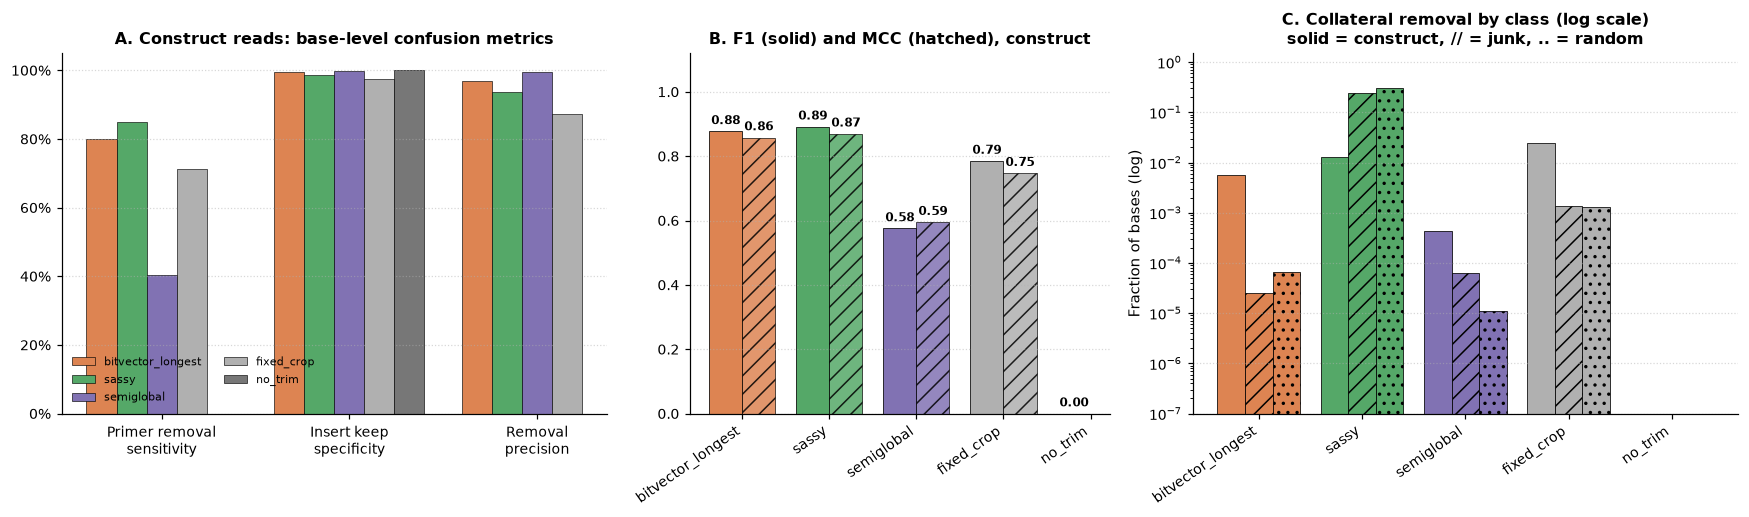

In [9]:
# Figure 1: Base-level confusion per read class (pooled over 3 noise profiles x 3 seeds)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1.3]})
cc = CLASS_CONFUSION.reset_index() if "method" not in CLASS_CONFUSION.columns else CLASS_CONFUSION
cc = cc.set_index(["method", "class"])

# A: construct sensitivity / specificity / precision per method
ax = axes[0]
metrics = [("removal_sensitivity", "Primer removal\nsensitivity"), ("keep_specificity", "Insert keep\nspecificity"), ("removal_precision", "Removal\nprecision")]
w = 0.8 / len(ALL_METHODS)
for k, m in enumerate(ALL_METHODS):
    vals = [cc.loc[(m, "construct"), key] if (m, "construct") in cc.index else np.nan for key, _ in metrics]
    ax.bar(np.arange(3) + (k - (len(ALL_METHODS) - 1) / 2) * w, vals, w, label=m, color=COLOURS[m], edgecolor="black", linewidth=0.4)
ax.set_xticks(range(3), [l for _, l in metrics])
ax.set_ylim(0, 1.05); ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("A. Construct reads: base-level confusion metrics")
ax.legend(ncol=2, fontsize=7.5, loc="lower left")
ax.grid(axis="y", linestyle=":", alpha=0.5)

# B: MCC / F1 / balanced accuracy per method
ax = axes[1]
sc = cc.xs("construct", level="class").reindex(ALL_METHODS)
x = np.arange(len(ALL_METHODS)); w = 0.38
b1 = ax.bar(x - w / 2, sc["f1"], w, color=[COLOURS[m] for m in ALL_METHODS], edgecolor="black", linewidth=0.5)
b2 = ax.bar(x + w / 2, sc["mcc"], w, color=[COLOURS[m] for m in ALL_METHODS], edgecolor="black", linewidth=0.5, hatch="//", alpha=0.85)
ax.set_ylim(0, 1.12); annotate(ax, b1, "{:.2f}"); annotate(ax, b2, "{:.2f}")
ax.set_xticks(x, ALL_METHODS, rotation=35, ha="right")
ax.set_title("B. F1 (solid) and MCC (hatched), construct")
ax.grid(axis="y", linestyle=":", alpha=0.5)

# C: negative controls - fraction of bases wrongly removed from construct, kept in junk/random
ax = axes[2]
neg = pd.DataFrame({
    "construct: insert bases lost (FPR)": [cc.loc[(m, "construct"), "fpr"] for m in ALL_METHODS],
    "junk: bases removed (1-spec.)": [cc.loc[(m, "junk"), "removal_sensitivity"] if (m, "junk") in cc.index else np.nan for m in ALL_METHODS],
    "random: bases removed (1-spec.)": [cc.loc[(m, "random"), "removal_sensitivity"] if (m, "random") in cc.index else np.nan for m in ALL_METHODS],
}, index=ALL_METHODS)
w = 0.8 / 3
for k, (col, hatch) in enumerate(zip(neg.columns, ["", "//", ".."])):
    ax.bar(x + (k - 1) * w, neg[col].replace(0, np.nan).fillna(1e-7), w, label=col, hatch=hatch,
           color=[COLOURS[m] for m in ALL_METHODS], edgecolor="black", linewidth=0.5)
ax.set_yscale("log"); ax.set_ylim(1e-7, 1.5)
ax.set_xticks(x, ALL_METHODS, rotation=35, ha="right")
ax.set_ylabel("Fraction of bases (log)")
ax.set_title("C. Collateral removal by class (log scale)\nsolid = construct, // = junk, .. = random")
ax.grid(axis="y", linestyle=":", alpha=0.5)
fig.tight_layout()
save_fig(fig, "fig1_confusion_by_class")
plt.show()

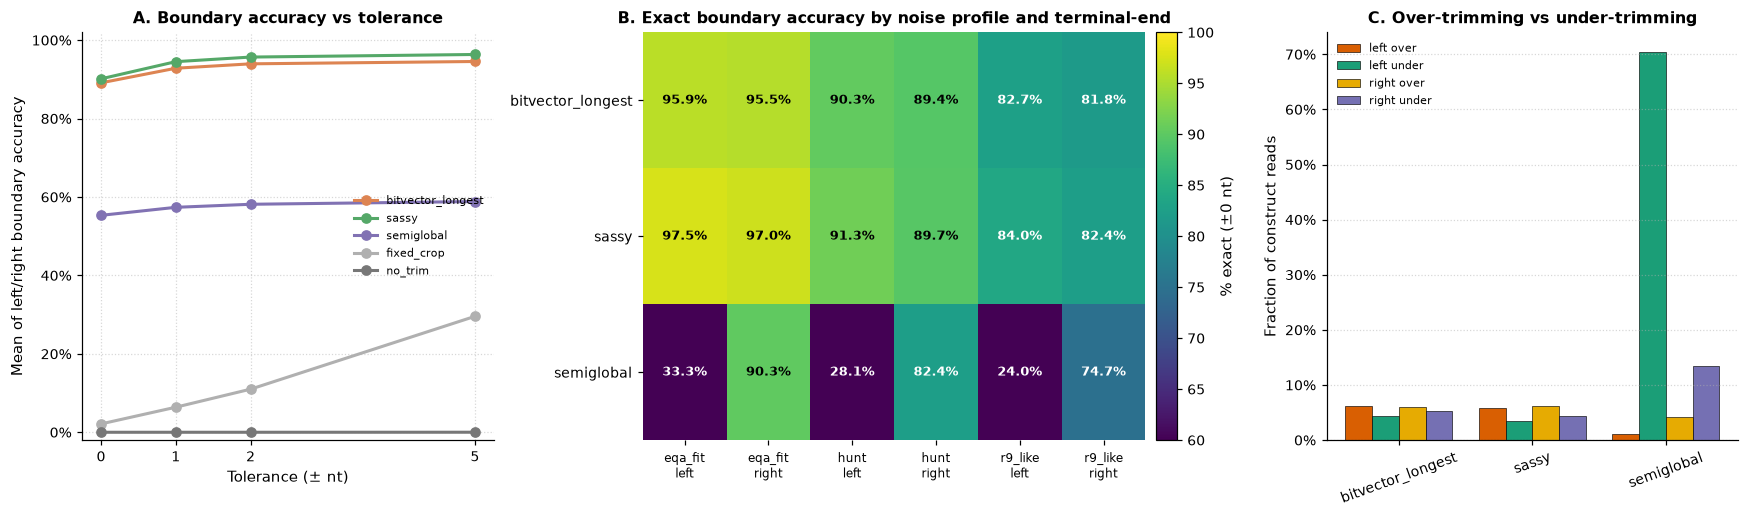

In [10]:
# Figure 2: Boundary accuracy - tolerance curves, per-profile heatmap, over/under-trim
bp = BOUNDARY_POOLED.copy()
byp = BOUNDARY_BY_PROFILE.reset_index() if "profile" not in BOUNDARY_BY_PROFILE.columns else BOUNDARY_BY_PROFILE.copy()
tols = list(BOUNDARY_TOLERANCES)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.3, 1]})

ax = axes[0]
for m in ALL_METHODS:
    if m not in bp.index: continue
    y = [(bp.loc[m, f"left_exact_within{t}"] + bp.loc[m, f"right_exact_within{t}"]) / 2 for t in tols]
    ax.plot(tols, y, marker="o", linewidth=2, color=COLOURS[m], label=m)
ax.set_xticks(tols); ax.set_xlabel("Tolerance (± nt)")
ax.set_ylabel("Mean of left/right boundary accuracy"); ax.set_ylim(-0.02, 1.02)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("A. Boundary accuracy vs tolerance"); ax.legend(fontsize=7.5)
ax.grid(True, linestyle=":", alpha=0.5)

ax = axes[1]
profiles = list(SCORING_PROFILES)
cols = [(p, e) for p in profiles for e in ("left", "right")]
mat = np.full((len(METHODS), len(cols)), np.nan)
for j, (p, e) in enumerate(cols):
    for i, m in enumerate(METHODS):
        row = byp[(byp["profile"] == p) & (byp["method"] == m)]
        if len(row): mat[i, j] = row[f"{e}_exact_within0"].iloc[0]
im = ax.imshow(mat * 100, cmap="viridis", vmin=60, vmax=100, aspect="auto")
ax.set_xticks(range(len(cols)), [f"{p}\n{e}" for p, e in cols], fontsize=8)
ax.set_yticks(range(len(METHODS)), METHODS)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat[i, j]:.1%}", ha="center", va="center", fontsize=8.5, fontweight="bold",
                color="white" if mat[i, j] * 100 < 85 else "black")
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="% exact (±0 nt)")
ax.set_title("B. Exact boundary accuracy by noise profile and terminal-end")

ax = axes[2]
x = np.arange(len(METHODS)); w = 0.2
parts = [("left_over_rate", "left over", "#d95f02"), ("left_under_rate", "left under", "#1b9e77"),
         ("right_over_rate", "right over", "#e6ab02"), ("right_under_rate", "right under", "#7570b3")]
for k, (col, lab, c) in enumerate(parts):
    ax.bar(x + (k - 1.5) * w, bp.loc[METHODS, col], w, label=lab, color=c, edgecolor="black", linewidth=0.4)
ax.set_xticks(x, METHODS, rotation=20)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Fraction of construct reads")
ax.set_title("C. Over-trimming vs under-trimming")
ax.legend(fontsize=7.5); ax.grid(axis="y", linestyle=":", alpha=0.5)
fig.tight_layout()
save_fig(fig, "fig2_boundary_accuracy")
plt.show()

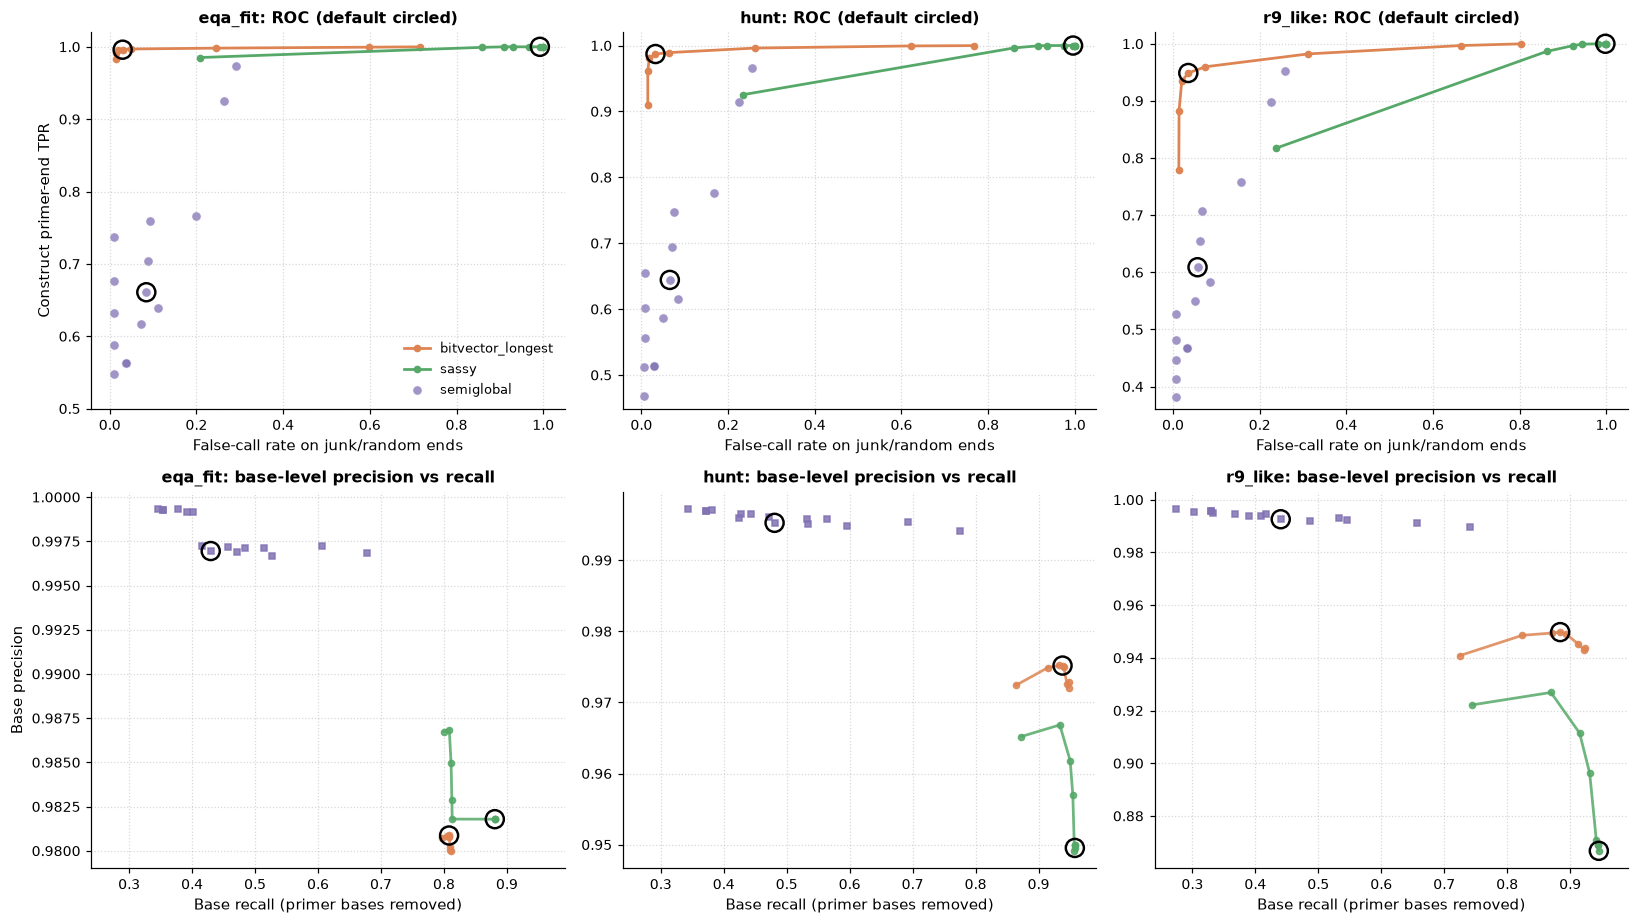

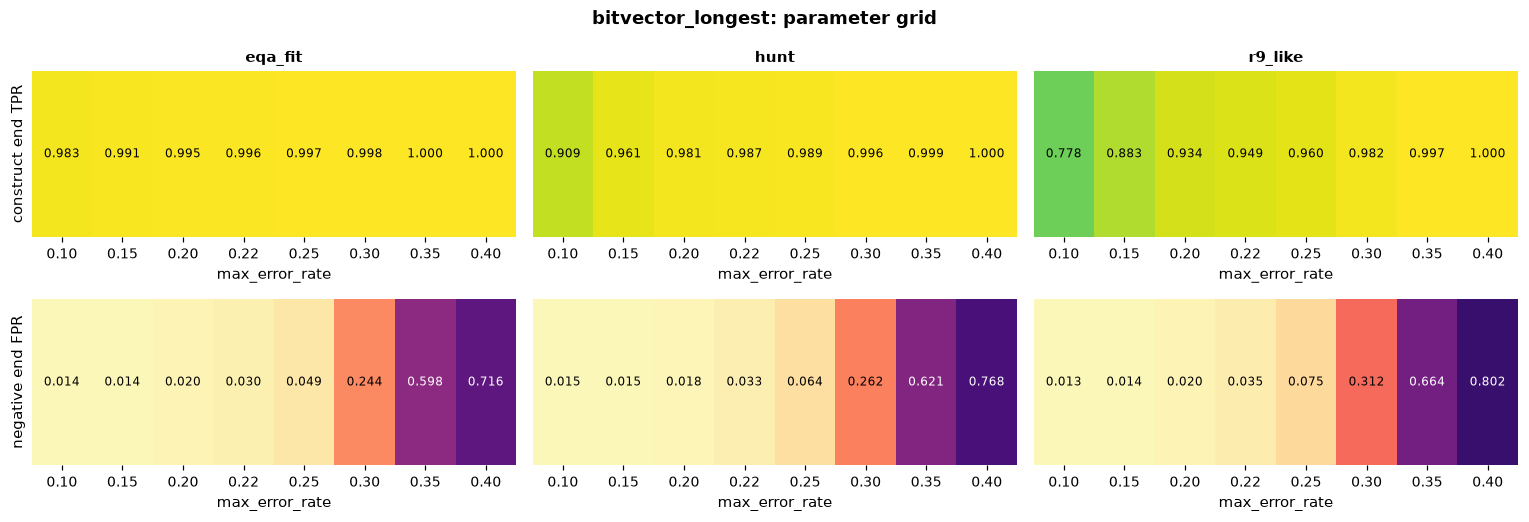

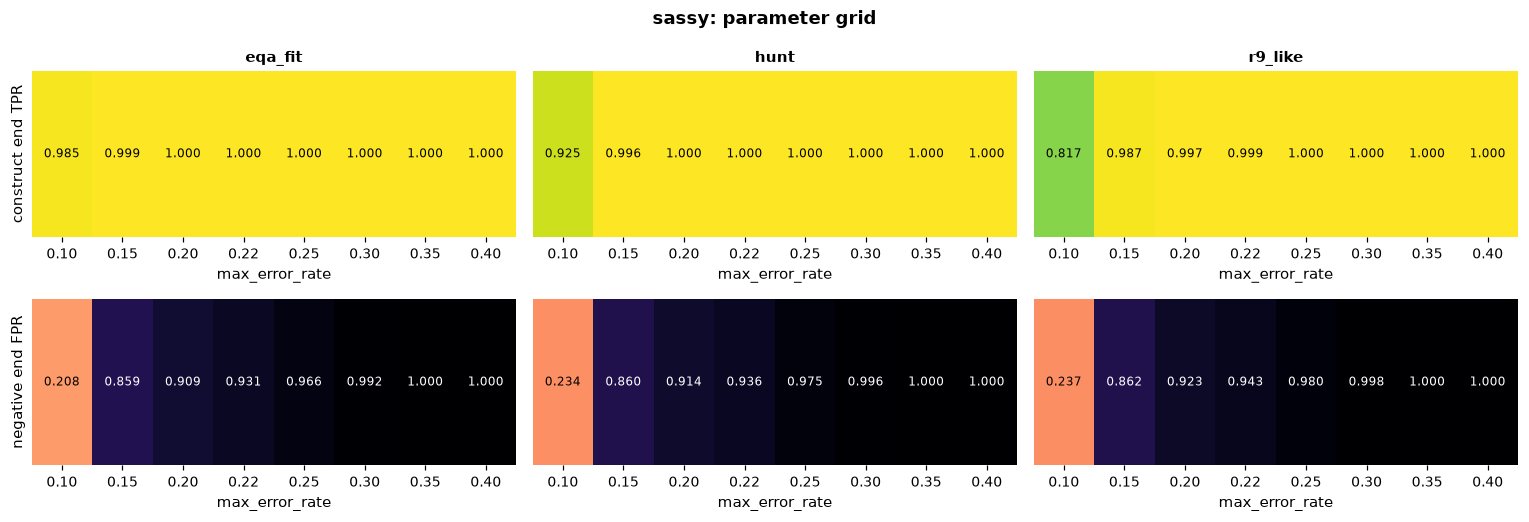

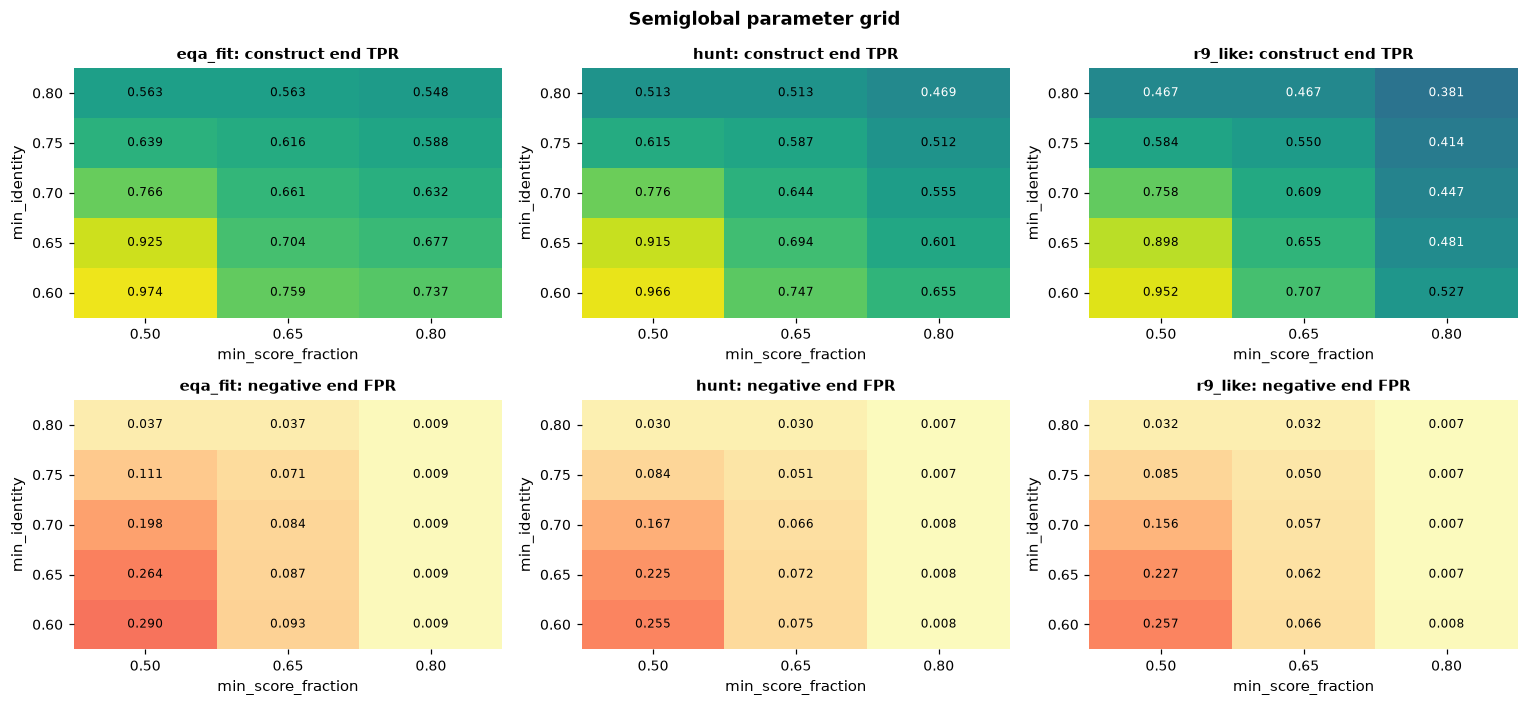

In [16]:
# Figure 3: Threshold sweep - ROC per profile + precision/recall trade-off + parameter grids
profiles = list(SCORING_PROFILES)
fig, axes = plt.subplots(2, len(profiles), figsize=(15, 8.5), sharex="row")
for j, profile in enumerate(profiles):
    sub = sweep[sweep["profile"] == profile]
    ax = axes[0, j]
    for m in METHODS:
        r = sub[sub["method"] == m]
        if m == "semiglobal":
            ax.scatter(r["negative_end_fpr"], r["per_end_tpr"], color=COLOURS[m], alpha=0.75, s=36, label=m, edgecolor="white", linewidth=0.4)
        else:
            r = r.sort_values("max_error_rate")
            ax.plot(r["negative_end_fpr"], r["per_end_tpr"], marker="o", ms=4, linewidth=1.8, color=COLOURS[m], label=m)
        d = r[r["is_default"]]
        if len(d):
            ax.scatter(d["negative_end_fpr"], d["per_end_tpr"], s=140, facecolors="none", edgecolors="black", linewidths=1.6, zorder=5)
    ax.set_title(f"{profile}: ROC (default circled)")
    ax.set_xlabel("False-call rate on junk/random ends")
    ax.set_ylim(min(0.5, sub["per_end_tpr"].min() - 0.02), 1.02)
    ax.grid(True, linestyle=":", alpha=0.5)
    axes[0, 0].set_ylabel("Construct primer-end TPR")

    ax = axes[1, j]
    for m in METHODS:
        r = sub[sub["method"] == m]
        if m != "semiglobal": r = r.sort_values("max_error_rate")
        ax.plot(r["base_recall"], r["base_precision"], marker="o" if m != "semiglobal" else "s", ms=4,
                linewidth=1.8 if m != "semiglobal" else 0, color=COLOURS[m], label=m, alpha=0.85)
        d = r[r["is_default"]]
        if len(d):
            ax.scatter(d["base_recall"], d["base_precision"], s=140, facecolors="none", edgecolors="black", linewidths=1.6, zorder=5)
    ax.set_title(f"{profile}: base-level precision vs recall")
    ax.set_xlabel("Base recall (primer bases removed)")
    ax.grid(True, linestyle=":", alpha=0.5)
    axes[1, 0].set_ylabel("Base precision")
axes[0, 0].legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "fig3_threshold_sweep")
plt.show()

# error-rate grids for methods with a max_error_rate parameter.
for method in ("bitvector_longest", "sassy"):
    method_sweep = sweep[sweep["method"] == method]
    fig, axes = plt.subplots(2, len(profiles), figsize=(14, 4.8), squeeze=False)
    for j, profile in enumerate(profiles):
        profile_sweep = method_sweep[method_sweep["profile"] == profile].sort_values("max_error_rate")
        error_rates = profile_sweep["max_error_rate"].to_numpy()
        for i, (metric, cmap, title) in enumerate((("per_end_tpr", "viridis", "construct end TPR"),
                                                   ("negative_end_fpr", "magma_r", "negative end FPR"))):
            ax = axes[i, j]
            values = profile_sweep[metric].to_numpy()
            im = ax.imshow(values[np.newaxis, :], cmap=cmap, aspect="auto", vmin=0, vmax=1)
            ax.set_xticks(range(len(error_rates)), [f"{rate:.2f}" for rate in error_rates])
            ax.set_yticks([])
            for k, value in enumerate(values):
                rgb = plt.get_cmap(cmap)(value)[:3]
                luminance = np.dot(rgb, [0.25, 0.75, 0.08])
                ax.text(k, 0, f"{value:.3f}", ha="center", va="center", fontsize=8,
                        color="black" if luminance > 0.5 else "white")
            if i == 0:
                ax.set_title(profile, fontsize=9.5)
            if j == 0:
                ax.set_ylabel(title)
            ax.set_xlabel("max_error_rate")
            for spine in ax.spines.values(): spine.set_visible(False)
    fig.suptitle(f"{method}: parameter grid", fontweight="bold")
    fig.tight_layout()
    save_fig(fig, f"fig3c_{method}_grid")
    plt.show()

# Semiglobal parameter grid: construct TPR and negative FPR as heatmaps per profile
sg = sweep[sweep["method"] == "semiglobal"]
fig, axes = plt.subplots(2, len(profiles), figsize=(14, 6.5))
for j, profile in enumerate(profiles):
    for i, (col, cmap, title) in enumerate([("per_end_tpr", "viridis", "construct end TPR"), ("negative_end_fpr", "magma_r", "negative end FPR")]):
        ax = axes[i, j]
        g = sg[sg["profile"] == profile].pivot(index="min_identity", columns="min_score_fraction", values=col).sort_index(ascending=False)
        im = ax.imshow(g.to_numpy(), cmap=cmap, aspect="auto", vmin=0, vmax=1)
        ax.set_xticks(range(g.shape[1]), [f"{c:.2f}" for c in g.columns]); ax.set_yticks(range(g.shape[0]), [f"{r:.2f}" for r in g.index])
        for a in range(g.shape[0]):
            for b in range(g.shape[1]):
                value = g.iat[a, b]
                rgb = plt.get_cmap(cmap)(value)[:3]
                luminance = np.dot(rgb, [0.25, 0.75, 0.08])
                ax.text(b, a, f"{value:.3f}", ha="center", va="center", fontsize=8,
                        color="black" if luminance > 0.5 else "white")
        ax.set_title(f"{profile}: {title}", fontsize=9.5)
        ax.set_xlabel("min_score_fraction"); ax.set_ylabel("min_identity")
        for spine in ax.spines.values(): spine.set_visible(False)
fig.suptitle("Semiglobal parameter grid", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig3b_semiglobal_grid")
plt.show()

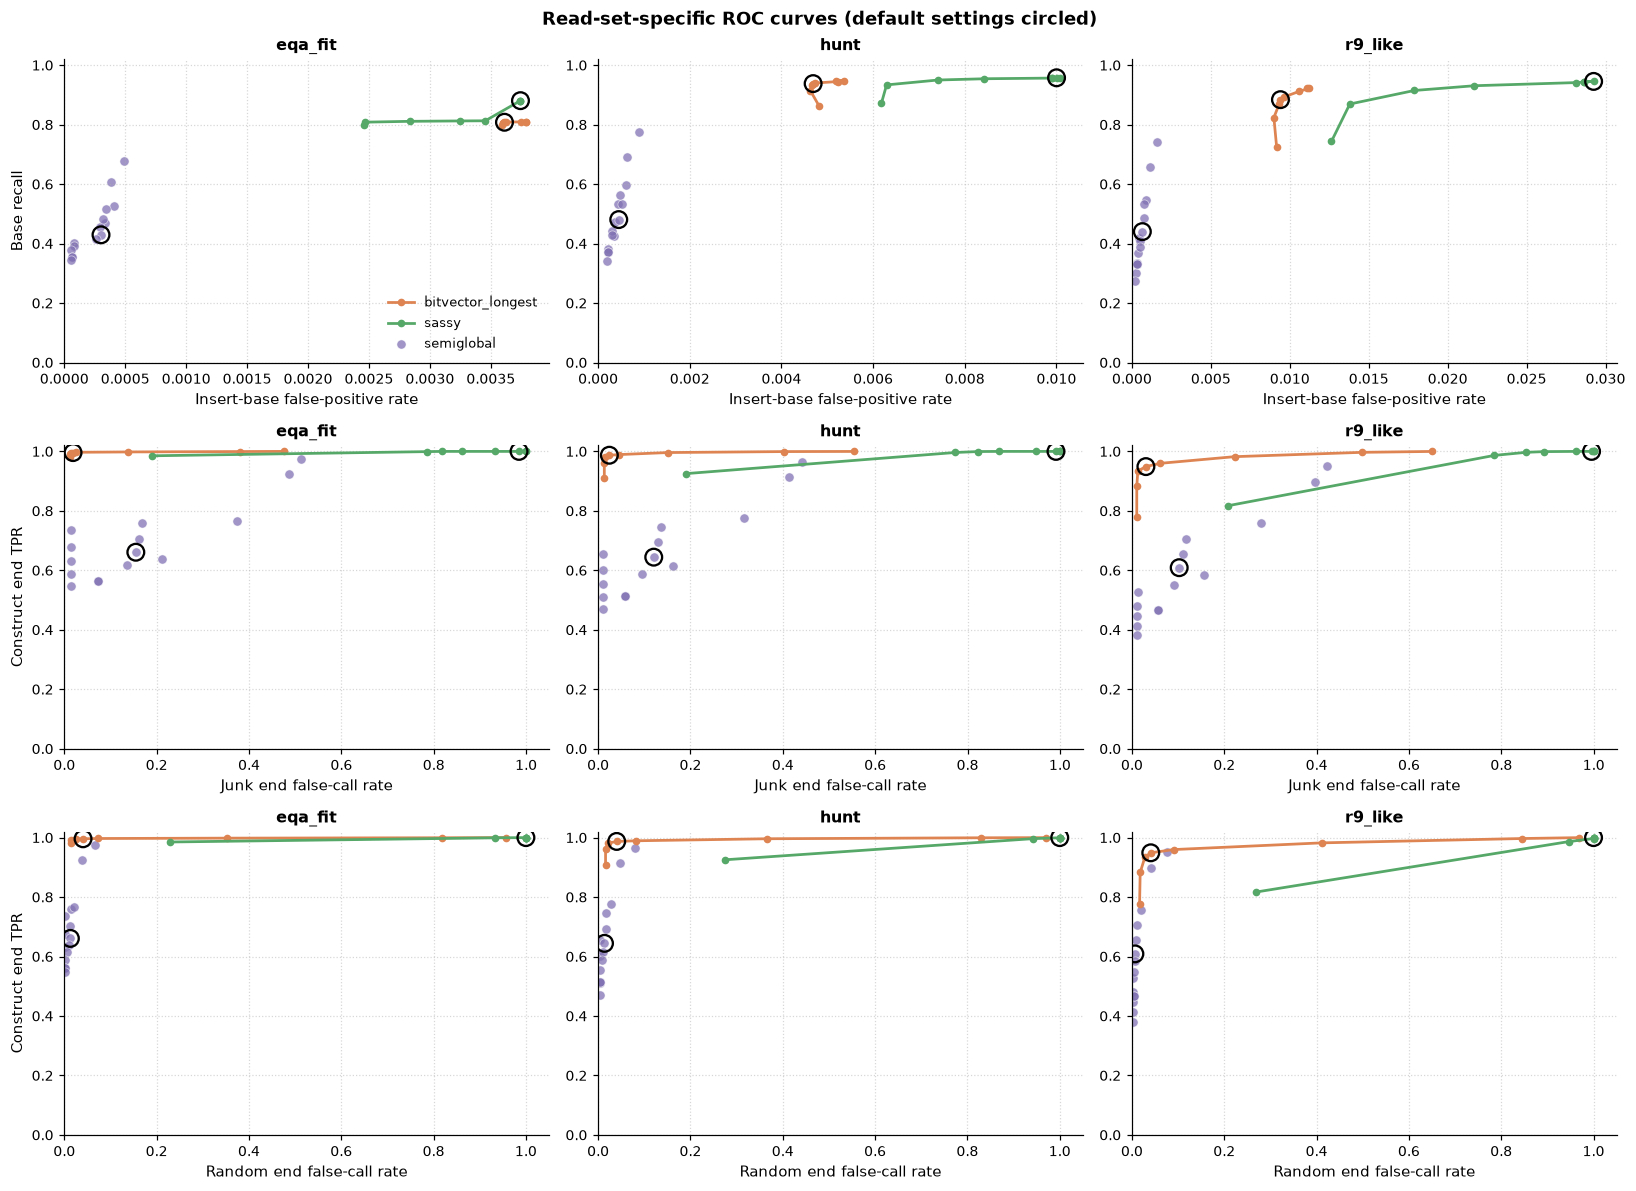

In [13]:
# Figure 3d: Read-set-specific ROC curves
roc_config = ["profile", "method", "max_error_rate", "min_identity", "min_score_fraction"]
negative_rates = (
    null_model.groupby(roc_config + ["class"], dropna=False)
    .agg(false_call_ends=("false_call_ends", "sum"), ends=("ends", "sum"))
    .reset_index()
)
negative_rates["class_end_fpr"] = negative_rates["false_call_ends"] / negative_rates["ends"]

roc_rows = (
    ("construct", "insert_base_fpr", "base_recall", "Insert-base false-positive rate", "Base recall"),
    ("junk", None, "per_end_tpr", "Junk end false-call rate", "Construct end TPR"),
    ("random", None, "per_end_tpr", "Random end false-call rate", "Construct end TPR"),
)
fig, axes = plt.subplots(len(roc_rows), len(profiles), figsize=(15, 11), squeeze=False)
for i, (read_class, fpr_column, tpr_column, x_label, y_label) in enumerate(roc_rows):
    for j, profile in enumerate(profiles):
        ax = axes[i, j]
        for method in METHODS:
            r = sweep[(sweep["profile"] == profile) & (sweep["method"] == method)].copy()
            if read_class != "construct":
                class_rates = negative_rates[
                    (negative_rates["profile"] == profile)
                    & (negative_rates["method"] == method)
                    & (negative_rates["class"] == read_class)
                ]
                r = r.merge(class_rates[roc_config + ["class_end_fpr"]], on=roc_config, how="left", validate="one_to_one")
            if method != "semiglobal":
                r = r.sort_values("max_error_rate")
            x = r[fpr_column] if read_class == "construct" else r["class_end_fpr"]
            y = r[tpr_column]
            if method == "semiglobal":
                ax.scatter(x, y, color=COLOURS[method], alpha=0.75, s=36, label=method, edgecolor="white", linewidth=0.4)
            else:
                ax.plot(x, y, marker="o", ms=4, linewidth=1.8, color=COLOURS[method], label=method)
            default = r[r["is_default"]]
            default_x = default[fpr_column] if read_class == "construct" else default["class_end_fpr"]
            if len(default):
                ax.scatter(default_x, default[tpr_column], s=120, facecolors="none", edgecolors="black", linewidths=1.5, zorder=5)
        ax.set_title(profile)
        ax.set_xlabel(x_label)
        ax.set_xlim(left=0)
        ax.set_ylim(0, 1.02)
        ax.grid(True, linestyle=":", alpha=0.5)
        if j == 0:
            ax.set_ylabel(y_label)
axes[0, 0].legend(loc="lower right")
fig.suptitle("Read-set-specific ROC curves (default settings circled)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig3d_read_set_roc")
plt.show()

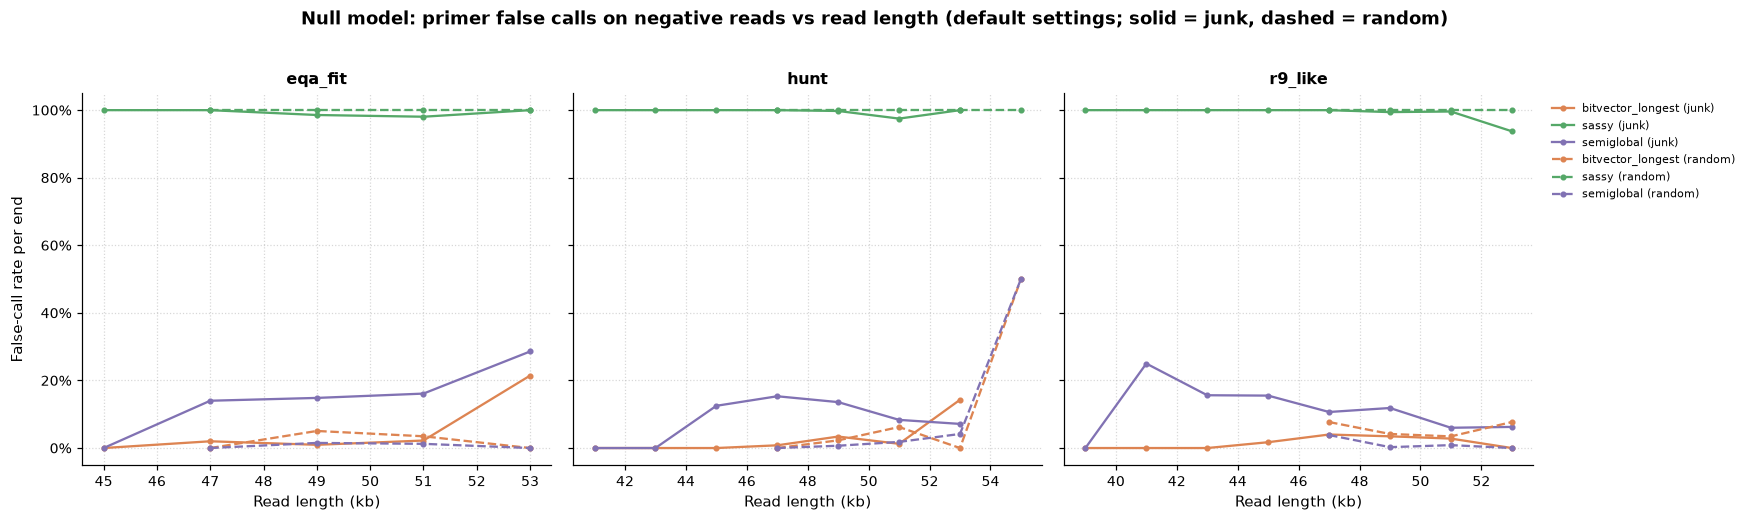

In [11]:
# Figure 4: Null model - false-call rate on junk/random reads by length, default settings
nm = null_model[null_model["is_default"]].copy()
nm["mid"] = np.floor((nm["length_lower"] + nm["length_upper"]) / 2 / 2000) * 2000 + 1000  # re-bin to 2 kb for stability
nm["false_call_ends"] = nm["false_call_ends"].astype(float)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, profile in zip(axes, profiles):
    for cls, ls in (("junk", "-"), ("random", "--")):
        for m in METHODS:
            f = nm[(nm["profile"] == profile) & (nm["method"] == m) & (nm["class"] == cls)]
            if f.empty: continue
            g = f.groupby("mid")[["false_call_ends", "ends"]].sum()
            ax.plot(g.index / 1000, g["false_call_ends"] / g["ends"], linestyle=ls, color=COLOURS[m], linewidth=1.5, marker="o", ms=3,
                    label=f"{m} ({cls})")
    ax.set_title(f"{profile}")
    ax.set_xlabel("Read length (kb)")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(True, linestyle=":", alpha=0.5)
axes[0].set_ylabel("False-call rate per end")
axes[-1].legend(fontsize=7, ncol=1, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Null model: primer false calls on negative reads vs read length (default settings; solid = junk, dashed = random)", fontweight="bold", y=1.02)
fig.tight_layout()
save_fig(fig, "fig4_null_model")
plt.show()

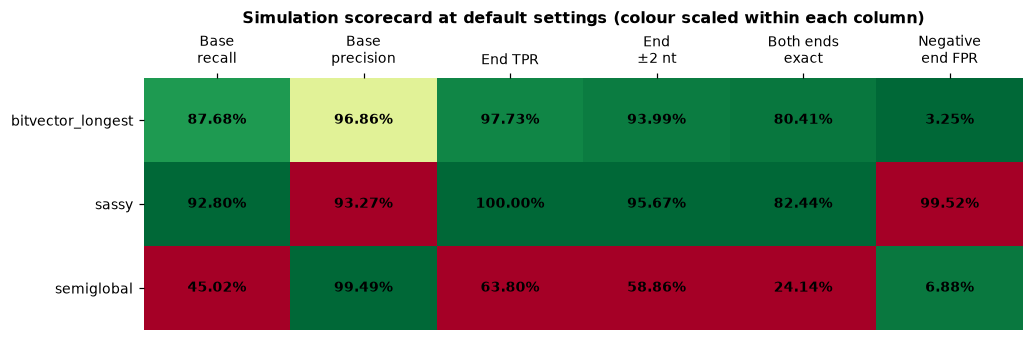

In [12]:
# Figure 5: Scorecard at default settings (mean over noise profiles)
d = sweep[sweep["is_default"]].groupby("method")[["base_precision", "base_recall", "per_end_tpr", "negative_end_fpr", "left_within2", "right_within2", "both_exact"]].mean().reindex(METHODS)
d["end_within2"] = (d["left_within2"] + d["right_within2"]) / 2
score = d[["base_recall", "base_precision", "per_end_tpr", "end_within2", "both_exact", "negative_end_fpr"]]
labels = ["Base\nrecall", "Base\nprecision", "End TPR", "End\n±2 nt", "Both ends\nexact", "Negative\nend FPR"]
norm = score.copy()
for c in score.columns:
    r = score[c].max() - score[c].min()
    n = (score[c] - score[c].min()) / r if r > 0 else pd.Series(0.5, index=score.index)
    norm[c] = 1 - n if c == "negative_end_fpr" else n
fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.imshow(norm.to_numpy(), cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(labels)), labels); ax.xaxis.tick_top()
ax.set_yticks(range(len(METHODS)), METHODS)
for i in range(score.shape[0]):
    for j in range(score.shape[1]):
        ax.text(j, i, f"{score.iat[i, j]:.2%}", ha="center", va="center", fontsize=9, fontweight="bold")
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Simulation scorecard at default settings (colour scaled within each column)", pad=36)
fig.tight_layout()
save_fig(fig, "fig5_scorecard")
plt.show()